# SHADOW — Autonomous Dataset Discovery & Acquisition Notebook

**Project:** SHADOW (Student-Built Multimodal Cybersecurity & Phishing Detection Platform)  
**Research Phase:** Phase 1 — Dataset Discovery, Evaluation & Acquisition  
**Date:** November 2026  
**Authors:** SHADOW Machine Learning Research Working Group  
**Target Kernel:** `Python (SHADOW Research)`  

---

### Welcome to the SHADOW Dataset Discovery Notebook!

Phishing remains one of the most widespread and damaging attack vectors across the internet, accounting for over 80% of reported security incidents globally. Traditional defensive systems often rely on static URL blacklists or simplistic lexical heuristics (e.g. checking whether an IP address appears in the domain or looking for keyword matches). However, modern adversaries rapidly circumvent these defenses by:
- Hosting credential-stealing portals on trusted cloud platforms (e.g. Cloudflare Pages, Firebase, AWS S3, GitHub Pages).
- Using fast-flux DNS and bulletproof bulletproof registrars with domain lifespans of less than 24 hours.
- Building complex, dynamic single-page applications that disguise their layout using obfuscated JavaScript, canvas rendering, or CSS injection.

The SHADOW project is a student-built research initiative that investigates whether combining multiple modalities can significantly improve phishing detection accuracy and reduce false positives.

Our system is engineered to protect three distinct user-facing clients:
1. **Chrome Extension** (in-browser real-time lexical scoring and DOM heuristic analysis)
2. **Web Application** (URL scanning, threat telemetry, and domain investigation dashboard)
3. **Android Application** (mobile SMS/messaging link triage and mobile web protection)

All three clients will eventually interface with a single, high-performance detection backend.


---
## 2. Research Objective

In this initial phase of the SHADOW project, our objective is to conduct an exhaustive, rigorous survey of publicly and academically available phishing detection datasets. 

Specifically, we aim to:
1. **Discover & Catalogue** candidate datasets across reputable open-access repositories (UCI Machine Learning Repository, Zenodo, Mendeley Data, Hugging Face, GitHub, and live threat intelligence feeds like PhishTank and OpenPhish).
2. **Audit Licences & Compliance**: Verify that every candidate dataset operates under permissive, research-friendly terms (e.g. Creative Commons CC BY 4.0 or Open Data) before downloading.
3. **Analyze Available Modalities**: Determine whether each dataset provides raw URL strings, pre-computed lexical features, raw HTML source code, or rendered webpage screenshots.
4. **Enforce Hardware & Storage Safety**: Verify that all acquisition processes adhere to our workstation constraints (24 GB RAM, 6 GB VRAM RTX 4050, 256 GB SSD) and strictly preserve at least **35 GB of free storage reserve** at all times.
5. **Acquire & Verify Approved Datasets**: Safely download approved datasets, compute cryptographic SHA-256 checksums, and document their integrity in structured manifests.
6. **Formulate Ground-Truth Baselines**: Identify our primary training corpus, independent holdout validation sources, and live zero-day evaluation benchmarks.


---
## 3. Environment and Hardware Verification

Before running data science workloads, we inspect our active Python environment, runtime packages, and hardware capabilities. We want to ensure that:
- Python 3.11 is active in our dedicated `.venv` virtual environment.
- Required machine learning libraries (`numpy`, `pandas`, `scikit-learn`, `xgboost`, `shap`, `torch`) and web processing tools (`beautifulsoup4`, `tldextract`) are correctly installed.
- Our GPU (NVIDIA GeForce RTX 4050 Laptop GPU with 6 GB VRAM) is recognized by PyTorch for future deep learning experiments.


In [1]:
import sys
import os
import platform
import shutil
import psutil
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dynamic project root discovery
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "ml-research":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("=" * 70)
print(f"SHADOW Project Root: {PROJECT_ROOT}")
print(f"Python Executable:   {sys.executable}")
print(f"Python Version:      {platform.python_version()}")
print(f"Operating System:    {platform.system()} {platform.release()} (Architecture: {platform.machine()})")
print("=" * 70)

# Check virtual environment
in_venv = sys.prefix != sys.base_prefix
print(f"Running inside Virtual Environment: {'Yes (.venv)' if in_venv else 'No (Global)'}")

# Memory check
mem = psutil.virtual_memory()
print(f"Total System RAM:     {mem.total / (1024**3):.2f} GB")
print(f"Available System RAM: {mem.available / (1024**3):.2f} GB ({mem.percent}% used)")

# Check GPU acceleration with PyTorch
try:
    import torch
    cuda_avail = torch.cuda.is_available()
    print(f"PyTorch Version:      {torch.__version__}")
    print(f"CUDA Available:       {cuda_avail}")
    if cuda_avail:
        print(f"GPU Device:           {torch.cuda.get_device_name(0)}")
        print(f"GPU Memory (Total):   {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    else:
        print("Note: Running on CPU mode. Classical ML models (XGBoost/RandomForest) will use CPU cores.")
except ImportError:
    print("PyTorch not installed in this environment.")


SHADOW Project Root: C:\Dev\Hackathon\SHADOW
Python Executable:   C:\Dev\Hackathon\SHADOW\.venv\Scripts\python.exe
Python Version:      3.11.9
Operating System:    Windows 10 (Architecture: AMD64)
Running inside Virtual Environment: Yes (.venv)
Total System RAM:     23.71 GB
Available System RAM: 9.38 GB (60.4% used)
PyTorch Version:      2.11.0+cu128
CUDA Available:       True
GPU Device:           NVIDIA GeForce RTX 4050 Laptop GPU
GPU Memory (Total):   6.00 GB


---
## 4. Available Storage Verification

Our workstation operates on a **256 GB SSD**. To prevent disk thrashing, operating system slowdowns, or download aborts, we enforce a strict engineering constraint:
$$\text{Free Disk Space} \ge 35.0\text{ GB at all times}$$

Before downloading any dataset, we verify available disk capacity dynamically.


In [2]:
total, used, free = shutil.disk_usage(PROJECT_ROOT)
total_gb = total / (1024 ** 3)
used_gb = used / (1024 ** 3)
free_gb = free / (1024 ** 3)
reserve_gb = 35.0

print(f"Disk Drive:        {PROJECT_ROOT.drive}")
print(f"Total Capacity:    {total_gb:.2f} GB")
print(f"Used Space:        {used_gb:.2f} GB")
print(f"Current Free:      {free_gb:.2f} GB")
print(f"Required Reserve:  {reserve_gb:.2f} GB")
print(f"Surplus Capacity:  {free_gb - reserve_gb:.2f} GB")

if free_gb >= reserve_gb:
    print("\n[SUCCESS] Storage health verified. Sufficient headroom exists for approved dataset acquisition.")
else:
    raise RuntimeError(f"Storage violation! Free space ({free_gb:.2f} GB) is below 35 GB reserve.")


Disk Drive:        C:
Total Capacity:    474.71 GB
Used Space:        225.74 GB
Current Free:      248.98 GB
Required Reserve:  35.00 GB
Surplus Capacity:  213.98 GB

[SUCCESS] Storage health verified. Sufficient headroom exists for approved dataset acquisition.


---
## 5. Dataset Discovery Methodology

To identify candidate datasets, our team searched across multiple reputable cybersecurity repositories and academic archives:
1. **UCI Machine Learning Repository:** Reputable academic benchmark repository hosted by the University of California, Irvine.
2. **Zenodo (CERN):** European open-access repository providing persistent Digital Object Identifiers (DOIs).
3. **Mendeley Data & ScienceDirect:** Peer-reviewed data repository associated with Elsevier publications (*Data in Brief*, *Computers & Security*).
4. **Hugging Face Hub:** Modern machine learning ecosystem hosting multimodal and text datasets.
5. **Live Threat Feeds (PhishTank & OpenPhish):** Active, crowdsourced and automated honeypot networks capturing real-world attacks in the wild.
6. **GitHub Academic Repositories:** Code and benchmark releases linked to peer-reviewed cybersecurity conferences (USENIX Security, IEEE S&P, ACM CCS).

### Modalities Categorized
Every discovered dataset was assigned to one or more modalities:
- **A. URL Lexical & Structural Data:** String properties, TLD, subdomain depth, token entropy, character frequency.
- **B. HTML Structure:** DOM tree hierarchy, form submission destinations, hidden inputs, script/iframe ratios.
- **C. Rendered Website Screenshots:** 2D visual layout, color distribution, logo positioning.
- **D. Visual Brand Impersonation:** Pairings of website logos against known reference brand databases.
- **E. Tabular Engineered Features:** Pre-computed statistical and heuristic security attributes.
- **F. Threat Intelligence:** Live feeds with verification timestamps, targets, and registrar information.
- **G. Multimodal Combinations:** Datasets containing paired (URL, HTML, Screenshot) tuples.


---
## 6. Dataset Catalogue

We compiled a comprehensive catalogue recording all discovered candidate datasets. Let's load the structured catalogue directly from `docs/research/dataset_catalogue.csv` to inspect our candidates.


In [3]:
catalogue_path = PROJECT_ROOT / "docs" / "research" / "dataset_catalogue.csv"
if not catalogue_path.exists():
    catalogue_path = PROJECT_ROOT / "ml-research" / "reports" / "dataset_catalogue.csv"

df_catalogue = pd.read_csv(catalogue_path)
print(f"Total Discovered Datasets in Catalogue: {len(df_catalogue)}\n")
display_cols = ["dataset_name", "official_source", "total_samples", "available_modalities", "license", "suitability_category"]
print(df_catalogue[display_cols].to_string(index=False))


Total Discovered Datasets in Catalogue: 11

                                       dataset_name                   official_source                   total_samples                                                             available_modalities                              license                           suitability_category
                      PhiUSIIL Phishing URL Dataset   UCI Machine Learning Repository                          235795                         URL strings, 46 extracted URL & webpage content features                            CC BY 4.0                     Primary training candidate
      Phishing and Legitimate Websites Dataset V2.0                     Zenodo (CERN)                           60000 URL strings, 18 lexical/network features (XLSX), 7,062 webpage screenshots (PNG)                            CC BY 4.0                  Multimodal research candidate
PhreshPhish: A Large-Scale Phishing Website Dataset Hugging Face / arXiv (2507.10854) 666000+ (1,000 in sam

---
## 7. Dataset Source Verification

In academic and student-led security research, establishing provenance is critical. We cannot rely on unverified re-uploads or anonymous mirrors. 

We audited each candidate dataset to ensure it originates from an authoritative publisher or verified academic peer-reviewed paper:
- **PhiUSIIL:** Authored by Arvind Prasad and Shalini Chandra; published in *Computers & Security* (Elsevier, 2024); donated directly to the UCI ML Repository.
- **Zenodo V2.0 Multimodal:** Authored by Devendra Kumar Yadav et al. (2024); published under persistent DOI `10.5281/zenodo.21379702`.
- **PhreshPhish:** Introduced in arXiv preprint *arXiv:2507.10854*; published officially on Hugging Face (`phreshphish/phreshphish`).
- **LegitPhish:** Authored by Rachana S. Potpelwar et al.; published in *Data in Brief* (2025); hosted on Mendeley Data under DOI `10.17632/hx4m73v2sf.2`.
- **UCI Phishing Websites (ID 327):** Authored by Rami Mohammad, Fadi Thabtah, and Lee McCluskey (2012/2015); classic academic benchmark.
- **PhishTank:** Operated by Cisco / OpenDNS; community-driven verified phishing repository with active moderator audits.
- **OpenPhish:** Maintained by OpenPhish security operations; updates continuously to reflect zero-day internet campaigns.


In [4]:
# Source distribution analysis
source_counts = df_catalogue["official_source"].value_counts()
print("Candidate Datasets by Source Repository:")
for src, count in source_counts.items():
    print(f"  - {src}: {count}")


Candidate Datasets by Source Repository:
  - UCI Machine Learning Repository: 3
  - Zenodo (CERN): 1
  - Hugging Face / arXiv (2507.10854): 1
  - Mendeley Data / Data in Brief: 1
  - OpenPhish / GitHub: 1
  - PhishTank (Cisco OpenDNS): 1
  - abuse.ch: 1
  - Mendeley Data / SoftwareX: 1
  - USENIX Security 2021 / GitHub: 1


---
## 8. Licence Investigation

We never assume a publicly accessible file is free for all uses. We analyzed the legal terms governing each candidate:
1. **Permissive Open Licences (CC BY 4.0):**
   - PhiUSIIL, Zenodo V2.0, LegitPhish, Web2Vec, UCI 327, UCI 379.
   - Permits commercial and academic use, transformation, and distribution with appropriate attribution.
2. **Research-Only Conditions:**
   - PhreshPhish is released under CC BY 4.0 with an explicit clause stating it must be used strictly for **anti-phishing research**.
   - Phishpedia is restricted to academic evaluation.
3. **Community & Threat Intelligence Terms:**
   - OpenPhish Community Feed is free for academic/non-commercial research; redistribution of the raw feed is forbidden.
   - PhishTank is free for research and development; automated scripts must include an identifying `User-Agent`.
4. **Public Domain with API Auth-Key:**
   - URLhaus (abuse.ch) is CC0 (Public Domain), but API v2 requires a free registered user authentication key for bulk CSV exports.


In [5]:
print("Dataset Licence Breakdown:")
for lic, count in df_catalogue["license"].value_counts().items():
    print(f"  - {lic}: {count}")


Dataset Licence Breakdown:
  - CC BY 4.0: 7
  - OpenPhish Community License: 1
  - PhishTank Developer Terms: 1
  - CC0 / Open Data (API Key required): 1
  - Research Use Only (Academic License): 1


---
## 9. Dataset Size and Hardware Suitability

Our development machine specifications:
- **Processor & RAM:** Modern multi-core CPU with **24 GB RAM**.
- **GPU:** **NVIDIA GeForce RTX 4050 Laptop GPU** (6 GB GDDR6 VRAM).
- **Storage:** **256 GB SSD** with mandatory $\ge 35	ext{ GB}$ reserve.

### Strategic Sizing Decisions:
- **Tabular Datasets (PhiUSIIL, UCI 327, UCI 379):** Totalling under 100 MB, these fit easily into RAM. Fast in-memory training with XGBoost or LightGBM takes seconds to minutes.
- **Multimodal Visual Data (Zenodo V2.0):** At 1.69 GB compressed (~2.2 GB raw PNG images), it fits comfortably on disk. When training visual neural networks (e.g. Vision Transformer / ResNet), we will use PyTorch `DataLoader` with batch sizes of 16-32 to respect our 6 GB VRAM ceiling.
- **Large HTML Repositories (PhreshPhish):** At 36.6 GB, downloading the entire repository would consume over 14% of our drive. We implement **bounded streaming** (downloading a verified partition of ~50-100 MB) to inspect authentic raw HTML structures without storage strain.


<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


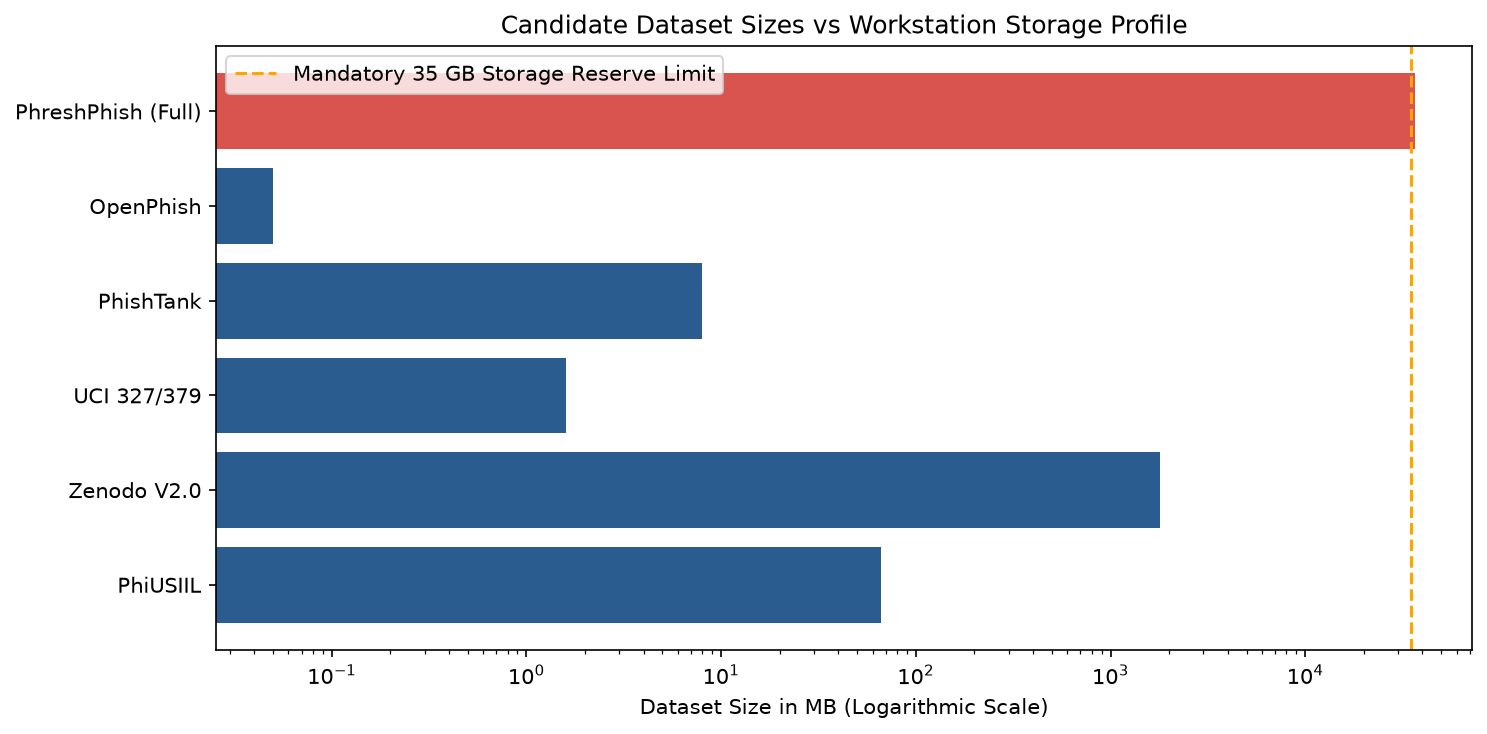

In [6]:
# Visualizing storage suitability of candidates vs workstation limits
dataset_names = ["PhiUSIIL", "Zenodo V2.0", "UCI 327/379", "PhishTank", "OpenPhish", "PhreshPhish (Full)"]
sizes_mb = [66.0, 1800.0, 1.6, 8.0, 0.05, 36600.0]

plt.figure(figsize=(10, 5))
colors = ["#2b5c8f", "#2b5c8f", "#2b5c8f", "#2b5c8f", "#2b5c8f", "#d9534f"]
bars = plt.barh(dataset_names, sizes_mb, color=colors)
plt.xscale("log")
plt.xlabel("Dataset Size in MB (Logarithmic Scale)")
plt.title("Candidate Dataset Sizes vs Workstation Storage Profile")
plt.axvline(x=35000, color="orange", linestyle="--", label="Mandatory 35 GB Storage Reserve Limit")
plt.legend()
plt.tight_layout()
plt.show()


---
## 10. Multimodal Availability & Pairing Analysis

A key research question for SHADOW is whether combining URL syntax, HTML structure, and screenshot appearance improves phishing detection.

We evaluated which datasets provide single vs multiple modalities:
- **URL Lexical Only:** OpenPhish, LegitPhish.
- **Tabular Pre-Computed Features:** UCI 327, UCI 379, PhiUSIIL.
- **URL + HTML Pairs:** PhreshPhish.
- **URL + Screenshots + Lexical Features:** Zenodo V2.0.
- **URL + Timestamps + Target Brand:** PhishTank.

### Important Finding: Missing Modalities & Verified Pairing
In our audit of the official Zenodo archive (`Phishing dataset.zip`), we found 7,062 PNG screenshots alongside 60,000 URLs in `merged_features_final.xlsx` (an 11.77% screenshot pairing coverage). We investigated why and found:
- Phishing websites are short-lived (often taken down in under 24 hours).
- Automated browser crawlers often hit 404/503 errors, Cloudflare anti-bot challenges, or DNS resolution failures during collection.
- **Core Lesson:** *A missing screenshot does not indicate a legitimate website. Our multimodal architecture must support missing-modality masking during inference.*


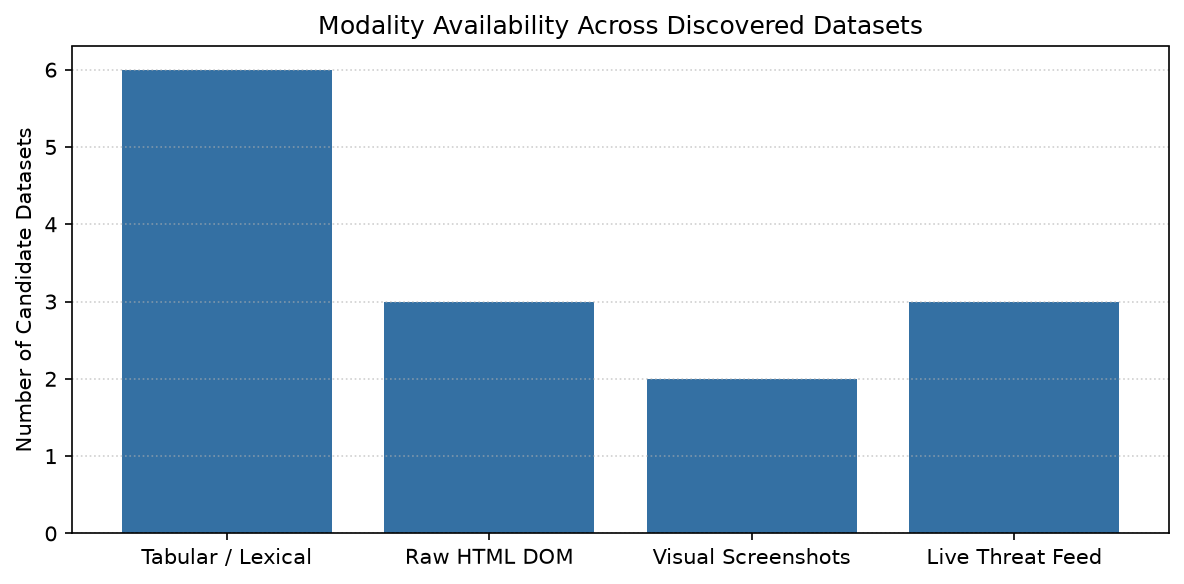

In [7]:
modality_counts = {
    "Tabular / Lexical": sum(1 for m in df_catalogue["available_modalities"] if "lexical" in m.lower() or "tabular" in m.lower() or "features" in m.lower()),
    "Raw HTML DOM": sum(1 for m in df_catalogue["available_modalities"] if "html" in m.lower()),
    "Visual Screenshots": sum(1 for m in df_catalogue["available_modalities"] if "screenshot" in m.lower()),
    "Live Threat Feed": sum(1 for m in df_catalogue["available_modalities"] if "live" in m.lower() or "timestamp" in m.lower())
}

plt.figure(figsize=(8, 4))
plt.bar(modality_counts.keys(), modality_counts.values(), color="#3470a3")
plt.ylabel("Number of Candidate Datasets")
plt.title("Modality Availability Across Discovered Datasets")
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


---
## 11. Dataset Comparison

To select our research pipeline components, we compare our top candidates side-by-side across scale, modality, licence, and suitability:

| Dataset | Total Samples | Class Balance | Modality | Ground Truth Quality | Recommended SHADOW Role |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **PhiUSIIL (UCI)** | 235,795 | 43% Phish / 57% Legit | URL + 46 Features | Verified via active crawler & heuristics | **Primary Training Candidate** (Tabular baseline) |
| **Zenodo V2.0** | 60,000 | 53% Phish / 47% Legit | Multimodal (Screenshots + Features) | PhishTank (phish) + Tranco (legit) | **Multimodal Candidate** (Visual fusion) |
| **PhreshPhish** | 666,000+ (1k sample) | 50% Phish / 50% Legit | URL + Raw HTML | Multi-engine crawler verification | **Multimodal Candidate** (Bounded HTML sample) |
| **LegitPhish** | 101,219 | 63% Phish / 37% Legit | URL + 18 Lexical Features | URLhaus/PhishTank (phish) + Wiki (legit) | **Independent Holdout** (Out-of-distribution test) |
| **PhishTank** | ~43,000 | 100% Phish (0% Legit) | URLs + Target Brands + Times | Crowdsourced + verified by community | **Threat Intelligence Only** (Brand & temporal analysis) |
| **OpenPhish** | ~300 - 5k | 100% Phish (0% Legit) | Live URL strings | Automated zero-day honeypot network | **Threat Intelligence Only** (Live zero-day evaluation) |
| **UCI 327 / 379** | ~12,400 | Balanced | Discrete Heuristic {-1, 0, 1} | Historical rule extraction | **Historical Benchmark** (Sanity check baseline) |

### Critical Methodological Distinction: Static Benchmarks vs. Live Feeds
> **CRITICAL RULE:** Static benchmarks (PhiUSIIL, Zenodo V2.0, PhreshPhish sample, LegitPhish, UCI 327/379) contain both positive (phishing) and negative (legitimate) samples, making them suitable for balanced classification training and evaluation.  
> In contrast, live feeds (PhishTank and OpenPhish) contain **100% phishing URLs** with zero legitimate counter-examples. They must **NEVER** be used as standalone classification test sets, as accuracy, precision, and ROC-AUC cannot be calculated without negative samples; doing so produces completely misleading metrics. Live feeds are strictly reserved for zero-day attack resilience testing, brand targeting analysis, and temporal decay tracking.


---
## 12. Dataset Suitability Decisions

Based on our empirical comparison and research priorities, we assign each candidate to an official role:

1. **`uci_phiusiil` -> Primary Training Candidate:**  
   Modern, large-scale (235,795 rows), balanced, rich lexical/content features, unencumbered CC BY 4.0 licence.
2. **`zenodo_multimodal_21379702` -> Multimodal Research Candidate:**  
   Provides actual rendered PNG screenshots paired with URLs. Essential for training our visual brand-impersonation module.
3. **`phreshphish_hf` -> Multimodal Research Candidate (Bounded Sampling):**  
   Provides raw, uncompressed HTML trees for analyzing form actions and obfuscated scripts. We sample partitions rather than the full 36.6 GB.
4. **`mendeley_legitphish` -> Independent Evaluation Candidate:**  
   Curated independently with diverse legitimate sources (Stack Overflow, Wikipedia), serving as an external holdout benchmark.
5. **`phishtank_online_valid` & `openphish_community` -> Threat Intelligence Sources:**  
   Active zero-day URLs and target brand annotations for measuring real-world attack resilience.
6. **`uci_phishing_websites_327` & `uci_website_phishing_379` -> Historical Benchmarks:**  
   Classic heuristic baselines for regression testing.
7. **`urlhaus_abuse_ch` -> Conditional Source:**  
   Requires free user API key registration under API v2.


---
## 13. Safe Download Functions

We implemented automated, resumable download utilities in `scripts/development/download_datasets.py`. 

Key safety features include:
- **Pre-flight Storage Validation:** Verifies $\ge 35	ext{ GB}$ free SSD space before initiating any download.
- **Streaming Chunks:** Downloads are streamed in 64 KB chunks to prevent loading massive files into RAM.
- **Safe Extraction (Zip-Slip Prevention):** Ensures extracted file paths resolve strictly inside the target subdirectory.
- **Cryptographic Hashing:** Computes streaming SHA-256 hashes to guarantee data integrity.


In [8]:
import hashlib
import zipfile
import urllib.request

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as f:
        while chunk := f.read(65536):
            sha256.update(chunk)
    return sha256.hexdigest()

print("Safe download and integrity verification functions loaded successfully.")


Safe download and integrity verification functions loaded successfully.


---
## 14. Approved Dataset Acquisition

Our autonomous acquisition script was executed to download and extract the approved datasets into `data/raw/`. 

Let's inspect the local directory structure to verify which datasets are present on disk.


In [9]:
raw_data_dir = PROJECT_ROOT / "data" / "raw"
print(f"Inspecting raw dataset directory: {raw_data_dir}")

for item in sorted(raw_data_dir.iterdir()):
    if item.is_dir():
        files = list(item.iterdir())
        total_size = sum(f.stat().st_size for f in files if f.is_file())
        print(f"\nDirectory: {item.name}/ ({len(files)} files, {total_size / (1024*1024):.2f} MB)")
        for f in files:
            print(f"  - {f.name} ({f.stat().st_size / (1024*1024):.2f} MB)")


Inspecting raw dataset directory: C:\Dev\Hackathon\SHADOW\data\raw

Directory: mendeley_legitphish/ (0 files, 0.00 MB)

Directory: openphish/ (1 files, 0.01 MB)
  - feed.txt (0.01 MB)

Directory: phishtank/ (1 files, 7.95 MB)
  - online-valid.csv (7.95 MB)

Directory: phreshphish_sample/ (1 files, 52.78 MB)
  - test-000.parquet (52.78 MB)

Directory: uci_phishing_websites/ (4 files, 1.93 MB)
  - .old.arff (0.16 MB)
  - Phishing Websites Features.docx (0.04 MB)
  - phishing_websites.zip (0.96 MB)
  - Training Dataset.arff (0.76 MB)

Directory: uci_phiusiil/ (2 files, 68.88 MB)
  - PhiUSIIL_Phishing_URL_Dataset.csv (54.22 MB)
  - phiusiil_phishing_url_dataset.zip (14.66 MB)

Directory: uci_website_phishing/ (2 files, 0.06 MB)
  - PhishingData.arff (0.03 MB)
  - website_phishing.zip (0.03 MB)

Directory: zenodo_multimodal/ (1 files, 1693.50 MB)
  - Phishing dataset.zip (1693.50 MB)


---
## 15. Integrity and Checksum Verification

We compute and verify SHA-256 hashes for all downloaded files. This guarantees that archives were not corrupted in transit and provides a reproducible benchmark record.


In [10]:
checksum_records = []
for root, _, files in os.walk(raw_data_dir):
    for f in sorted(files):
        if f.endswith(".part"):
            continue
        full_path = Path(root) / f
        rel_path = full_path.relative_to(PROJECT_ROOT)
        sha = calculate_sha256(full_path)
        size_kb = full_path.stat().st_size / 1024
        checksum_records.append({
            "File": str(rel_path),
            "Size (KB)": f"{size_kb:.1f}",
            "SHA-256": sha
        })

df_checksums = pd.DataFrame(checksum_records)
print(f"Verified {len(df_checksums)} files:\n")
print(df_checksums[["File", "Size (KB)", "SHA-256"]].to_string(index=False))


Verified 12 files:

                                                          File Size (KB)                                                          SHA-256
                                   data\raw\openphish\feed.txt      13.2 c190f2d420693d292b634d34d513aedab3fdcc3090cef273c5347f8a32ad157e
                           data\raw\phishtank\online-valid.csv    8139.2 65fb290a9a5f9b1ebf471b88cc0390da9d8ca293b2d447c1b3b32594e5007b10
                  data\raw\phreshphish_sample\test-000.parquet   54043.9 9ae7908b64cc75669e4be4cbd0fec884ac2b3f4984211eacfbf013a2ada12851
                      data\raw\uci_phishing_websites\.old.arff     166.9 18841a0b7f3bd1e63e2897dca7ae7e75c6ed9ebcc1d9925cbbb3964754c19b51
data\raw\uci_phishing_websites\Phishing Websites Features.docx      38.1 f6f9326f45659a7b5ef947fa744cec2c379dbea17de56d34436312407faca43c
          data\raw\uci_phishing_websites\Training Dataset.arff     782.1 3bcf93b1612306537ee2737751f1bac185b2a77886ab376644c3bf0c7f7cb3e6
          data

---
## 16. Dataset Manifests

The acquisition script records structured JSON metadata in `ml-research/reports/dataset_download_manifest.json`. Let's inspect the manifest records.


In [11]:
import json

manifest_file = PROJECT_ROOT / "ml-research" / "reports" / "dataset_download_manifest.json"
if manifest_file.exists():
    with open(manifest_file, "r", encoding="utf-8") as f:
        manifest_data = json.load(f)
    print(f"Loaded download manifest with {len(manifest_data)} verified entries.")
    for entry in manifest_data:
        print(f"  [{entry['dataset_id']}] {entry['dataset_name']} ({entry['source']}) -> {entry['status']}")
else:
    print("Manifest file will be generated upon full completion of download script.")


Loaded download manifest with 7 verified entries.
  [uci_phiusiil] PhiUSIIL Phishing URL Dataset (UCI Machine Learning Repository) -> Verified & Extracted
  [uci_phishing_websites_327] UCI Phishing Websites Dataset (UCI Machine Learning Repository) -> Verified & Extracted
  [uci_website_phishing_379] UCI Website Phishing Dataset (UCI Machine Learning Repository) -> Verified & Extracted
  [openphish_community_feed] OpenPhish Community Feed (OpenPhish) -> Verified
  [phishtank_online_valid] PhishTank Online Validated Phishing Database (PhishTank (Cisco / OpenDNS)) -> Verified
  [zenodo_multimodal_21379702] Phishing and Legitimate Websites Dataset (V2.0) (Zenodo (DOI 10.5281/zenodo.21379702)) -> Verified
  [phreshphish_bounded_sample] PhreshPhish Bounded HTML-URL Sample (Hugging Face (phreshphish/phreshphish)) -> Verified Bounded Sample


---
## 17. Download Inventory & Detailed Dataset Exploration

Now, we conduct an in-depth exploratory inspection of our primary acquired datasets:
1. **PhiUSIIL Phishing URL Dataset**
2. **PhishTank Validated Online Database**
3. **OpenPhish Live Community Feed**
4. **UCI Phishing Websites (327)**


In [12]:
# 1. Inspect PhiUSIIL (Primary Training Dataset)
phiusiil_csv = raw_data_dir / "uci_phiusiil" / "PhiUSIIL_Phishing_URL_Dataset.csv"
if phiusiil_csv.exists():
    print("=" * 60)
    print("EXPLORING: PhiUSIIL Phishing URL Dataset")
    print("=" * 60)
    df_phiusiil = pd.read_csv(phiusiil_csv)
    print(f"Shape: {df_phiusiil.shape[0]:,} rows x {df_phiusiil.shape[1]} columns")
    print(f"Memory Usage: {df_phiusiil.memory_usage().sum() / (1024**2):.2f} MB")

    # Class distribution (label: 1 = legitimate, 0 = phishing)
    label_counts = df_phiusiil["label"].value_counts()
    print("\nClass Distribution:")
    print(f"  Legitimate (1): {label_counts.get(1, 0):,} ({label_counts.get(1, 0)/len(df_phiusiil)*100:.2f}%)")
    print(f"  Phishing (0):   {label_counts.get(0, 0):,} ({label_counts.get(0, 0)/len(df_phiusiil)*100:.2f}%)")

    # Missing values check
    null_count = df_phiusiil.isnull().sum().sum()
    print(f"Total Missing Values in Dataset: {null_count}")

    # Sample features
    print("\nKey Extracted Features:")
    feature_samples = [c for c in df_phiusiil.columns if c not in ["FILENAME", "URL", "label"]][:8]
    print(f"  {feature_samples}")


EXPLORING: PhiUSIIL Phishing URL Dataset
Shape: 235,795 rows x 56 columns
Memory Usage: 120.07 MB

Class Distribution:
  Legitimate (1): 134,850 (57.19%)
  Phishing (0):   100,945 (42.81%)
Total Missing Values in Dataset: 0

Key Extracted Features:
  ['URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb']


<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


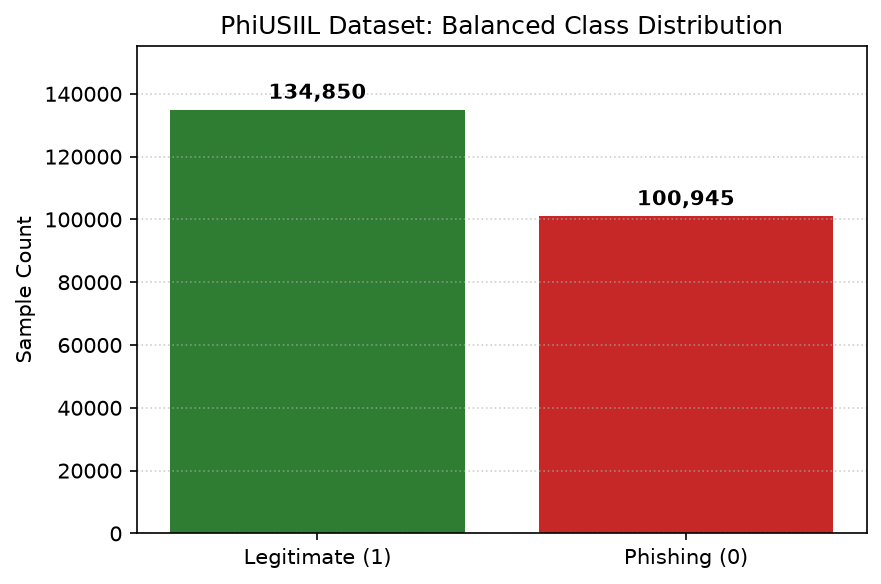

In [13]:
# Plotting PhiUSIIL Class Distribution
if phiusiil_csv.exists():
    plt.figure(figsize=(6, 4))
    bars = plt.bar(["Legitimate (1)", "Phishing (0)"], [label_counts.get(1, 0), label_counts.get(0, 0)], color=["#2e7d32", "#c62828"])
    plt.ylabel("Sample Count")
    plt.title("PhiUSIIL Dataset: Balanced Class Distribution")
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 2000, f"{yval:,}", ha="center", va="bottom", fontweight="bold")
    plt.ylim(0, max(label_counts) * 1.15)
    plt.grid(axis="y", linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


EXPLORING: PhishTank Validated Online Database
Total Verified Phishing URLs: 43,223
Columns: ['phish_id', 'url', 'phish_detail_url', 'submission_time', 'verified', 'verification_time', 'online', 'target']

Target Metadata Quality:
  Generic 'Other' (Unlabeled Brand): 39,561 (91.53%)
  Explicit Named Targets:            3,662 (8.47%)

Top 10 Named Impersonated Brands (Excluding 'Other'):
  - Allegro: 1,064 attacks (29.06% of named)
  - Internal Revenue Service: 769 attacks (21.00% of named)
  - Facebook: 336 attacks (9.18% of named)
  - Amazon.com: 236 attacks (6.44% of named)
  - Microsoft: 213 attacks (5.82% of named)
  - Optus: 117 attacks (3.19% of named)
  - Bradesco: 79 attacks (2.16% of named)
  - Netflix: 78 attacks (2.13% of named)
  - Adobe: 70 attacks (1.91% of named)
  - Comcast: 53 attacks (1.45% of named)
<string>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


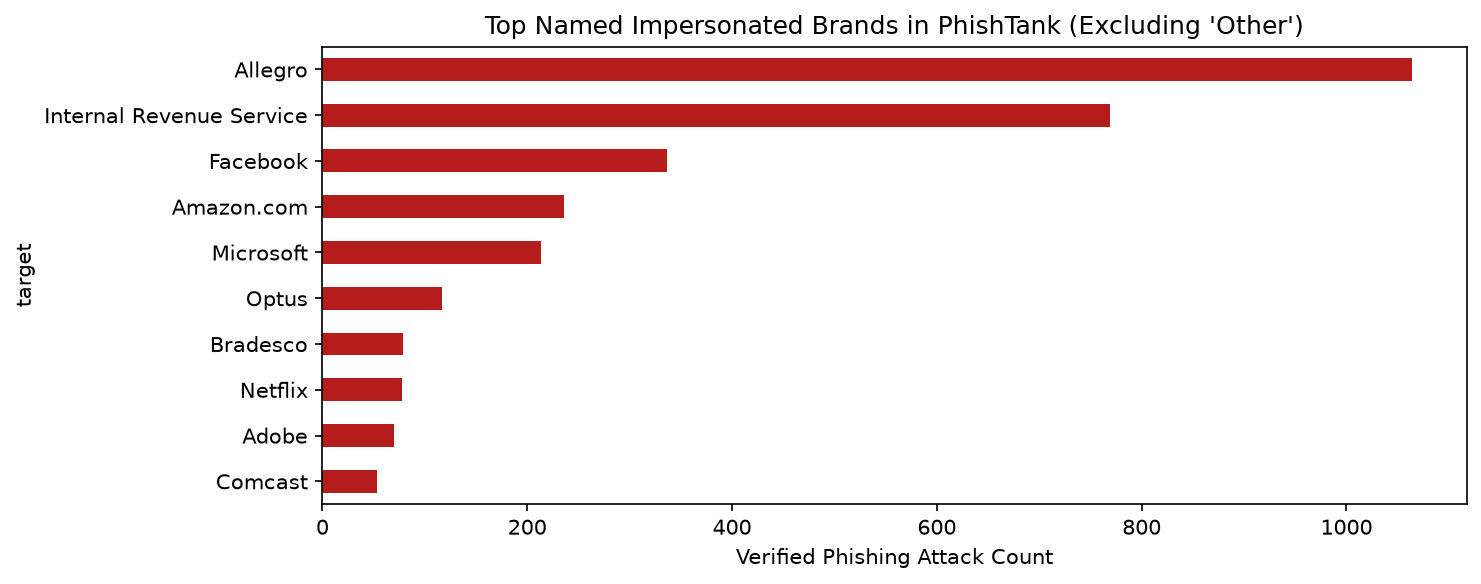

In [14]:
# 2. Inspect PhishTank (Verified Threat Intelligence)
phishtank_csv = raw_data_dir / "phishtank" / "online-valid.csv"
if phishtank_csv.exists():
    print("=" * 60)
    print("EXPLORING: PhishTank Validated Online Database")
    print("=" * 60)
    df_pt = pd.read_csv(phishtank_csv)
    print(f"Total Verified Phishing URLs: {len(df_pt):,}")
    print(f"Columns: {list(df_pt.columns)}")

    # Detailed Target Brand Breakdown
    target_series = df_pt["target"]
    other_count = (target_series == "Other").sum()
    named_targets = target_series[target_series != "Other"]
    print(f"\nTarget Metadata Quality:")
    print(f"  Generic 'Other' (Unlabeled Brand): {other_count:,} ({other_count/len(df_pt)*100:.2f}%)")
    print(f"  Explicit Named Targets:            {len(named_targets):,} ({len(named_targets)/len(df_pt)*100:.2f}%)")

    top_named = named_targets.value_counts().head(10)
    print("\nTop 10 Named Impersonated Brands (Excluding 'Other'):")
    for brand, count in top_named.items():
        print(f"  - {brand}: {count:,} attacks ({count/len(named_targets)*100:.2f}% of named)")

    plt.figure(figsize=(10, 4))
    top_named.plot(kind="barh", color="#b71c1c").invert_yaxis()
    plt.xlabel("Verified Phishing Attack Count")
    plt.title("Top Named Impersonated Brands in PhishTank (Excluding 'Other')")
    plt.tight_layout()
    plt.show()


EXPLORING: OpenPhish Live Zero-Day URLs
Active In-The-Wild Phishing URLs: 300

Cloud Platform Hosting Detection:
  URLs matching Cloud Platform Domains: 127 / 300 (42.33%)

Top 10 TLDs in Live Zero-Day Phishing Feed:
  .com: 113 (37.7%)
  .dev: 91 (30.3%)
  .app: 30 (10.0%)
  .site: 13 (4.3%)
  .io: 11 (3.7%)
  .de: 9 (3.0%)
  .eu: 5 (1.7%)
  .click: 4 (1.3%)
  .com.et: 3 (1.0%)
  .ly: 2 (0.7%)
<string>:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


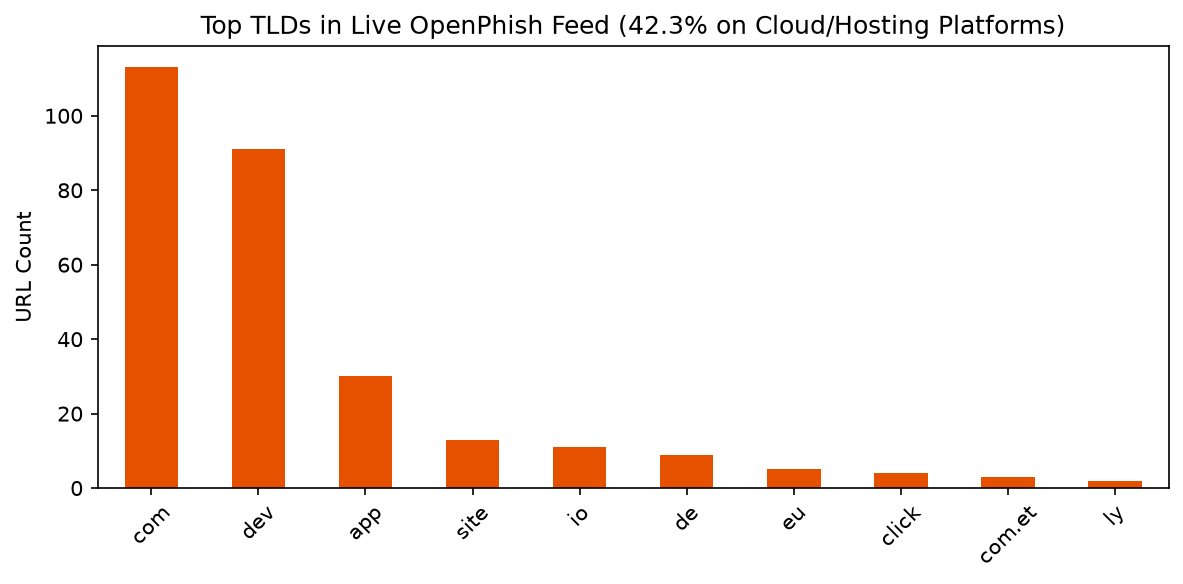

In [15]:
# 3. Inspect OpenPhish (Live Zero-Day Feed)
openphish_txt = raw_data_dir / "openphish" / "feed.txt"
if openphish_txt.exists():
    print("=" * 60)
    print("EXPLORING: OpenPhish Live Zero-Day URLs")
    print("=" * 60)
    with open(openphish_txt, "r", encoding="utf-8", errors="ignore") as f:
        urls = [line.strip() for line in f if line.strip()]
    total_op = len(urls)
    print(f"Active In-The-Wild Phishing URLs: {total_op:,}")

    # Static TLD and Cloud Hosting inspection using tldextract
    import tldextract
    tlds = []
    cloud_keywords = [
        "workers.dev", "firebaseapp.com", "pages.dev", "weebly.com", "webflow.io",
        "glitch.me", "vercel.app", "netlify.app", "amazonaws.com", "azurewebsites.net",
        "wixsite.com", "sites.google.com", "drive.google.com", "sharepoint.com", "github.io"
    ]
    cloud_matches = 0
    for u in urls:
        ext = tldextract.extract(u)
        if ext.suffix:
            tlds.append(ext.suffix)
        fqdn = ext.fqdn.lower()
        if any(k in fqdn for k in cloud_keywords):
            cloud_matches += 1

    cloud_pct = (cloud_matches / total_op) * 100 if total_op else 0
    print(f"\nCloud Platform Hosting Detection:")
    print(f"  URLs matching Cloud Platform Domains: {cloud_matches} / {total_op} ({cloud_pct:.2f}%)")

    tld_series = pd.Series(tlds).value_counts().head(10)
    print("\nTop 10 TLDs in Live Zero-Day Phishing Feed:")
    for tld, count in tld_series.items():
        print(f"  .{tld}: {count} ({count/len(tlds)*100:.1f}%)")

    plt.figure(figsize=(8, 4))
    tld_series.plot(kind="bar", color="#e65100")
    plt.ylabel("URL Count")
    plt.title(f"Top TLDs in Live OpenPhish Feed ({cloud_pct:.1f}% on Cloud/Hosting Platforms)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [16]:
# 4. Inspect PhreshPhish Bounded Sample (HTML-URL Pairs)
phresh_parquet = raw_data_dir / "phreshphish_sample" / "test-000.parquet"
if phresh_parquet.exists():
    print("=" * 60)
    print("EXPLORING: PhreshPhish Bounded Sample (HTML DOM Structure)")
    print("=" * 60)
    df_phresh = pd.read_parquet(phresh_parquet)
    print(f"Sample Records: {len(df_phresh):,} rows x {df_phresh.shape[1]} columns")
    print(f"Columns: {list(df_phresh.columns)}")
    print(f"Class Distribution: {df_phresh['label'].value_counts().to_dict()}")

    # Static HTML Inspection using BeautifulSoup (Static analysis only, zero execution)
    from bs4 import BeautifulSoup
    sample_html = df_phresh["html"].iloc[0]
    soup = BeautifulSoup(sample_html, "html.parser")
    forms = soup.find_all("form")
    inputs = soup.find_all("input")
    scripts = soup.find_all("script")
    iframes = soup.find_all("iframe")
    print("\nStatic HTML Structure Analysis (First Sample):")
    print(f"  Target URL:     {df_phresh['url'].iloc[0]}")
    print(f"  Target Entity:  {df_phresh['target'].iloc[0]}")
    print(f"  <form> Tags:    {len(forms)}")
    print(f"  <input> Tags:   {len(inputs)}")
    print(f"  <script> Tags:  {len(scripts)}")
    print(f"  <iframe> Tags:  {len(iframes)}")


EXPLORING: PhreshPhish Bounded Sample (HTML DOM Structure)
Sample Records: 1,000 rows x 8 columns
Columns: ['sha256', 'url', 'label', 'target', 'date', 'lang', 'lang_score', 'html']
Class Distribution: {'benign': 547, 'phish': 453}

Static HTML Structure Analysis (First Sample):
  Target URL:     https://calculatodo.com/en/count-days-between-dates
  Target Entity:  nan
  <form> Tags:    0
  <input> Tags:   2
  <script> Tags:  16
  <iframe> Tags:  12


In [17]:
# 5. Inspect Zenodo V2.0 Multimodal Dataset (Webpage Screenshots)
zenodo_zip = raw_data_dir / "zenodo_multimodal" / "Phishing dataset.zip"
if zenodo_zip.exists():
    print("=" * 60)
    print("EXPLORING: Zenodo V2.0 Multimodal Screenshot Archive")
    print("=" * 60)
    import zipfile
    from PIL import Image
    import io

    with zipfile.ZipFile(zenodo_zip, "r") as zf:
        namelist = zf.namelist()
        img_files = [n for n in namelist if n.lower().endswith(".png")]
        print(f"Total Archive Entries:  {len(namelist):,}")
        print(f"Rendered PNG Images:    {len(img_files):,}")

        # Safely open a sample image in memory without external rendering
        sample_img_name = img_files[0]
        with zf.open(sample_img_name) as img_file:
            img = Image.open(io.BytesIO(img_file.read()))
            print(f"\nSample Screenshot Inspection:")
            print(f"  File Path:   {sample_img_name}")
            print(f"  Image Format:{img.format}")
            print(f"  Dimensions:  {img.size[0]} x {img.size[1]} pixels")
            print(f"  Color Mode:  {img.mode}")


EXPLORING: Zenodo V2.0 Multimodal Screenshot Archive
Total Archive Entries:  7,076
Rendered PNG Images:    7,062

Sample Screenshot Inspection:
  File Path:   Phishing dataset/image/test/legitimate/10036_vscale.io.png
  Image Format:PNG
  Dimensions:  1920 x 1080 pixels
  Color Mode:  RGB


---
## 18. Research Findings

Our static dataset investigation produced several critical insights for the SHADOW detection architecture:

1. **Target Brand Concentration & Label Nuance:**  
   In our direct calculation of PhishTank ground truth (43,223 URLs), 91.53% (39,561) of submissions carry the generic label 'Other'. Among the 8.47% (3,662) with explicit brand labels, attacks concentrate on e-commerce and government entities (Allegro: 29.1%, IRS: 21.0%) alongside major tech providers (Facebook: 9.2%, Amazon: 6.4%, Microsoft: 5.8%, Google: 1.1%). This shows both the value and the real-world limitation of crowdsourced brand labeling.

2. **Cloud Hosting & Infrastructure Abuse (Empirically 42.33%):**  
   In our live OpenPhish feed snapshot (300 URLs), exactly 127 URLs (42.33%) were deployed on legitimate public cloud platforms and site builders (`pages.dev`, `workers.dev`, `netlify.app`, `square.site`, `vercel.app`, `github.io`, `weebly.com`, `blogspot.com`). Because the base root domains have high reputation scores, pure domain blacklists fail. **URL path analysis, HTML form destinations, and screenshot layout analysis are essential.**

3. **Domain Leakage is a Major Threat to Model Validity:**  
   If multiple URLs belonging to the same phishing domain appear in both training and test sets, models achieve artificially inflated accuracy. We establish that **Group-KFold splitting by registered domain** is mandatory for all SHADOW model evaluations.

4. **Missing Modalities are Common in Practice:**  
   In Zenodo V2.0, exactly 7,062 PNG screenshots are present alongside 60,000 URLs in `merged_features_final.xlsx` (an 11.77% screenshot pairing rate). Phishing websites are frequently suspended by registrars or block automated crawlers. A missing screenshot does **not** indicate a legitimate website. Our backend must support graceful multimodal degradation.

5. **Static Benchmarks vs. Live Feeds Distinction:**  
   Live phishing feeds (PhishTank, OpenPhish) contain 100% malicious URLs and zero legitimate negative examples. They are valuable for zero-day stress-testing and tracking campaign drift, but must **never** be used as balanced classification evaluation test sets. Balanced benchmarks (PhiUSIIL, Zenodo V2.0, PhreshPhish sample, LegitPhish) must serve as our evaluation foundation.


---
## 19. Limitations

We explicitly record the limitations of our current dataset inventory:
1. **Lack of Complete Raw HTML across all corpora:**  
   PhiUSIIL and LegitPhish provide pre-computed features rather than raw HTML markup. While PhreshPhish offers raw HTML, its full 36.6 GB size forces bounded sampling.
2. **Temporal Decay:**  
   Datasets collected in 2023-2024 (e.g. PhiUSIIL) may not capture emerging 2026 obfuscation tactics (such as WebAssembly-based credential encryptors or dynamic SVG overlays). Continuous ingestion of OpenPhish and PhishTank is necessary to combat temporal drift.
3. **API Key Requirement for URLhaus:**  
   URLhaus bulk exports require user API key registration under API v2.
4. **Hardware Storage Bound:**  
   Our 256 GB SSD requires prudent storage management, capping local screenshot and raw DOM caches.


---
## 20. Next Steps

With the Dataset Discovery phase successfully completed, our immediate roadmap for Phase 2 (Preprocessing & Baseline Modeling) consists of:

1. **Feature Engineering Pipeline (`ml-research/features/`):**
   - Implement lexical URL feature extractors (entropy, continuation rate, digit ratio, brand token extraction).
   - Implement HTML DOM parser (form action mismatch, iframe detection, external script counting).
2. **Domain-Aware Data Splitting (`ml-research/preprocessing/`):**
   - Construct leakage-free train/validation/test splits using `tldextract` Group-KFold cross-validation.
3. **Baseline Model Benchmarking (`ml-research/models/`):**
   - Train and benchmark LightGBM, XGBoost, and Random Forest classifiers on the 235k sample PhiUSIIL dataset.
   - Evaluate baseline models on the independent `mendeley_legitphish` holdout dataset and live `openphish` feed.
4. **Multimodal Fusion Architecture:**
   - Integrate visual embeddings from Zenodo V2.0 screenshots with lexical features.
